# 06 - Phân tích lỗi trên TEST (bước 7)
UIT-ViQuAD 2.0, mô hình `xlmr_large` (ensemble 3 seed `final_s42/43/44`, biến thể `min/64/20`, ngưỡng no-answer tune trên **dev**).

**Lưu ý giao thức (quan trọng):** test đã được chấm một lần ở notebook 05 và kết quả đã đóng băng. Notebook này **chỉ đọc lại dự đoán trên test để mô tả lỗi**; nó **không thay đổi bất kỳ quyết định nào** (công thức huấn luyện, biến thể hậu xử lý, ngưỡng, lựa chọn mô hình). Mọi nhận xét ở cuối là *quan sát*, không dùng để chỉnh lại cấu hình.

Cờ `ALLOW_TEST_READ=True` bên dưới là chỗ duy nhất trong notebook cho phép đọc test (`allow_test=True`).

In [1]:
import sys, re, bisect, logging, time, contextlib, io
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib
get_ipython().run_line_magic("matplotlib", "inline")  # inline PNG lưu vào output
import matplotlib.pyplot as plt
from src import evalkit as ek
from src.metrics import exact_match, f1_score
logging.basicConfig(level=logging.WARNING)
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80); pd.set_option("display.max_rows", 100)

ALLOW_TEST_READ = True   # chỉ để đọc dự đoán mô tả lỗi; KHÔNG dùng để chọn/tune bất cứ thứ gì
assert isinstance(ALLOW_TEST_READ, bool)
T0 = time.time()
M = "xlmr_large"
RUN_DIRS = [ROOT / "outputs" / "sweep" / "stage3" / M / f"{M}__final_s{s}" for s in (42, 43, 44)]

## 1. Dự đoán của ensemble trên test
Ngưỡng và biến thể được lấy lại **từ dev** (đúng như notebook 05, mục 5-9): `ek.tune_variant_grid` trên ensemble dev, kiểm tra biến thể = `min/64/20`; test chỉ được chấm với ngưỡng đó.

In [2]:
assert ALLOW_TEST_READ, "cần ALLOW_TEST_READ=True để đọc test"
# --- dev: biến thể + ngưỡng (không dùng test) ---
runs_dev = [ek.load_run(d) for d in RUN_DIRS]
ex_d, feats_d, extract_d = ek.build_eval_context(M, "dev", expected_hash=runs_dev[0]["dev"]["feature_hash"])
s_d, e_d, _, _ = ek.ensemble_logits(runs_dev)
choice, _ = ek.tune_variant_grid(ex_d, feats_d, s_d, e_d, extract_d)
assert (choice["null_variant"], choice["max_answer_length"], choice["n_best"]) == ek.DEFAULT_VARIANT, choice
thr = choice["threshold"]
print("biến thể:", ek.DEFAULT_VARIANT, "| ngưỡng dev của ensemble:", thr)

# --- test: chỉ đọc dự đoán ---
buf = io.StringIO()
prev = logging.root.manager.disable
logging.disable(logging.WARNING)
try:
    with contextlib.redirect_stdout(buf):
        rs = [ek.load_run(d, allow_test=True) for d in RUN_DIRS]
        ex, feats, extract = ek.build_eval_context(M, "test", allow_test=True, expected_hash=rs[0]["test"]["feature_hash"])
        s, e, _, _ = ek.ensemble_logits(rs, split="test", allow_test=True)
        sc = ek.rescore(ex, feats, s, e, extract, *ek.DEFAULT_VARIANT)
finally:
    logging.disable(prev)
print("WARNING: TEST SPLIT READ (chỉ mô tả lỗi)")

refs = ek.refs_of(ex)
rows = []
for r in ex:
    i = r["id"]; v = sc[i]
    pred = "" if v["diff"] > thr else v["text"]
    rows.append({"id": i, "context": r["context"], "question": r["question"], "gold": refs[i],
                 "gold_start": list(r["answers"]["answer_start"]), "plausible": list(r["plausible_answers"]["text"]),
                 "is_impossible": bool(r["is_impossible"]), "pred": pred, "diff": v["diff"], "span_text": v["text"],
                 "em": exact_match(pred, refs[i]), "f1": f1_score(pred, refs[i])})
df = pd.DataFrame(rows)
assert (df.is_impossible == (df.gold.str.len() == 0)).all()
print(f"n={len(df)} | EM={df.em.mean()*100:.2f} F1={df.f1.mean()*100:.2f} | NoAns n={df.is_impossible.sum()} acc={df[df.is_impossible].em.mean()*100:.2f} | HasAns F1={df[~df.is_impossible].f1.mean()*100:.2f}")

D:\00_Workspace\AI_Lab\RAG_official\Extractive_QA\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


biến thể: ('min', 64, 20) | ngưỡng dev của ensemble: 0.2820313215255695


n=3814 | EM=68.35 F1=77.89 | NoAns n=1161 acc=76.74 | HasAns F1=78.39


## 2. Quy tắc phân loại lỗi (EM = 0)
Mọi ví dụ có EM=0 được gán đúng **một** nhóm:
- **(a) NoAns, mô hình vẫn trả lời**: câu hỏi không có đáp án nhưng dự đoán khác rỗng. Ghi thêm có trùng một `plausible_answer` hay không.
- **(b) HasAns, mô hình dự đoán không có đáp án**: câu hỏi có đáp án nhưng dự đoán rỗng.
- **(c) HasAns, lệch biên**: span dự đoán (vị trí ký tự trong ngữ cảnh) giao với ít nhất một span vàng nhưng khác biên. Chia nhỏ: *sub-span* (nằm trọn trong vàng), *super-span* (chứa trọn vàng), *shifted* (giao một phần).
- **(d) HasAns, sai chỗ**: không giao với span vàng nào. Chia nhỏ: *cùng câu* với một span vàng hay *câu khác*; câu được tách bằng dấu `. ! ?` (hoặc xuống dòng).

In [3]:
def sent_idx(context):
    cuts = [m.end() for m in re.finditer(r"[.!?]+\s+|\n+", context)]
    return lambda pos: bisect.bisect_right(cuts, pos)

def locate(context, pred):
    p = context.find(pred)
    return (p, p + len(pred)) if p >= 0 and pred else None

def categorize(r):
    if r.em == 1: return "correct", ""
    if r.is_impossible:
        return "a_noans_answered", ("= plausible" if r.pred and any(exact_match(r.pred, [p]) == 1 for p in r.plausible) else "khác plausible")
    if not r.pred: return "b_hasans_pred_null", ""
    loc = locate(r.context, r.pred)
    golds = [(st, st + len(g)) for g, st in zip(r.gold, r.gold_start)]
    if loc is None:  # không định vị được: dùng F1 > 0 làm dấu hiệu giao nhau
        return ("c_overlap", "shifted") if r.f1 > 0 else ("d_wrong_place", "câu khác")
    ps, pe_ = loc
    ov = [(g0, g1) for g0, g1 in golds if ps < g1 and g0 < pe_]
    if ov:
        if any(ps >= g0 and pe_ <= g1 for g0, g1 in ov): return "c_overlap", "sub-span"
        if any(ps <= g0 and pe_ >= g1 for g0, g1 in ov): return "c_overlap", "super-span"
        return "c_overlap", "shifted"
    si = sent_idx(r.context)
    same = any(si(ps) == si(g0) or si(pe_ - 1) == si(g0) for g0, _ in golds)
    return "d_wrong_place", ("cùng câu" if same else "câu khác")

cat = df.apply(categorize, axis=1, result_type="expand")
df["category"], df["sub"] = cat[0], cat[1]
err = df[df.em == 0].copy()
assert len(err) == int((df.em == 0).sum()) and (err.category != "correct").all()
NAMES = {"a_noans_answered": "(a) NoAns nhưng trả lời", "b_hasans_pred_null": "(b) HasAns nhưng đoán rỗng",
         "c_overlap": "(c) giao span, lệch biên", "d_wrong_place": "(d) sai chỗ"}
tab = err.groupby("category").size().rename("n_errors").to_frame()
tab["% of errors"] = tab.n_errors / len(err) * 100
tab["% of all"] = tab.n_errors / len(df) * 100
tab.index = [NAMES[k] for k in tab.index]
tab.loc["TỔNG lỗi (EM=0)"] = [len(err), 100.0, len(err) / len(df) * 100]
display(tab.round(2))
sub = err.groupby(["category", "sub"]).size().rename("n").to_frame()
sub["% of errors"] = sub.n / len(err) * 100; sub["% of all"] = sub.n / len(df) * 100
display(sub.round(2))

,n_errors,% of errors,% of all
(a) NoAns nhưng trả lời,270,22.37,7.08
(b) HasAns nhưng đoán rỗng,316,26.18,8.29
"(c) giao span, lệch biên",478,39.60,12.53
(d) sai chỗ,143,11.85,3.75
TỔNG lỗi (EM=0),1207,100.00,31.65


n  % of errors  % of all
category           sub                                       
a_noans_answered   = plausible     143        11.85      3.75
                   khác plausible  127        10.52      3.33
b_hasans_pred_null                 316        26.18      8.29
c_overlap          shifted           9         0.75      0.24
                   sub-span        213        17.65      5.58
                   super-span      256        21.21      6.71
d_wrong_place      câu khác        105         8.70      2.75
                   cùng câu         38         3.15      1.00

## 3. Biểu đồ tỷ trọng các nhóm lỗi

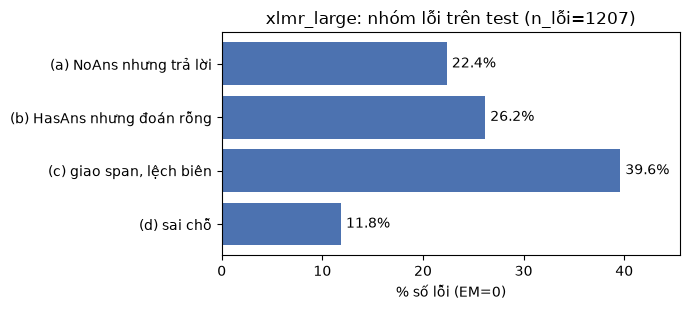

In [4]:
share = err.category.value_counts(normalize=True).reindex(list(NAMES)).fillna(0) * 100
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh([NAMES[k] for k in share.index][::-1], share.values[::-1], color="#4c72b0")
for y, v in enumerate(share.values[::-1]): ax.text(v + 0.5, y, f"{v:.1f}%", va="center")
ax.set_xlabel("% số lỗi (EM=0)"); ax.set_xlim(0, max(share.max() * 1.15, 1)); ax.set_title(f"{M}: nhóm lỗi trên test (n_lỗi={len(err)})")
plt.tight_layout()
display(fig); plt.close(fig)

## 4. Mẫu 50 ví dụ sai (phân tầng theo nhóm, seed 0)
Số mẫu mỗi nhóm tỉ lệ với số lỗi của nhóm (làm tròn bằng phần dư lớn nhất, tối thiểu 1 nếu nhóm không rỗng). Văn bản dài bị cắt.

In [5]:
def alloc(counts, k=50):
    raw = counts / counts.sum() * k
    n = np.floor(raw).astype(int).clip(lower=1)
    order = list((raw - np.floor(raw)).sort_values(ascending=False).index)
    i = 0
    while n.sum() < k: n[order[i % len(order)]] += 1; i += 1
    while n.sum() > k: n[n.idxmax()] -= 1
    return n

cut = lambda t, n=90: t if len(t) <= n else t[:n] + "..."
n_per = alloc(err.category.value_counts(), min(50, len(err)))
smp = pd.concat([g.sample(n=int(n_per[c]), random_state=0) for c, g in err.groupby("category")])
view = pd.DataFrame({"id": smp.id, "category": smp.category + smp["sub"].map(lambda x: f" / {x}" if x else ""),
                     "question": smp.question.map(cut), "gold": smp.gold.map(lambda g: cut(" | ".join(g)) if g else "(không có)"),
                     "pred": smp.pred.map(lambda p: cut(p) if p else "(rỗng)"), "f1": smp.f1.round(2)}).reset_index(drop=True)
print("mẫu mỗi nhóm:", n_per.to_dict(), "| tổng", len(view))
display(view)

mẫu mỗi nhóm: {'c_overlap': 20, 'b_hasans_pred_null': 13, 'a_noans_answered': 11, 'd_wrong_place': 6} | tổng 50


,id,category,question,gold,pred,f1
0,0003-0030-0001,a_noans_answered / = plausible,Tiền đề của sự kết hợp của NEP và FIRA là gì?,(không có),các mối quan tâm về sự độc lập năng lượng và sở hữu ngoại quốc trong lĩnh vự...,0.00
1,0009-0005-0003,a_noans_answered / = plausible,Nhân vật nào làm việc dưới trướng của Mitterrand?,(không có),Favre de Thierrens,0.00
2,0009-0039-0003,a_noans_answered / khác plausible,"Trong ngày chiếc tàu bị đánh đắm, TVNZ đã làm gì?",(không có),tìm cách tiếp cận một đoạn video được thực hiện ở phiên xét xử đầu tiên khi ...,0.00
3,0014-0008-0005,a_noans_answered / khác plausible,Cả ba Hoàng đế đều hài lòng vào thứ gì nhất?,(không có),đức tin vào Thượng đế và sự ủng hộ của Công giáo,0.00
4,0017-0050-0006,a_noans_answered / = plausible,Sau khi nhận ra việc truyền tải thông tin liên lạc điện tín giữa dịch vụ RCA...,(không có),thông điệp được giao bằng xe đạp,0.00
5,0015-0014-0008,a_noans_answered / = plausible,Số người theo Stalin đã chết thông qua thanh trừng tại Mông Cổ là bao nhiêu?,(không có),trên 30.000 người,0.00
6,0009-0020-0003,a_noans_answered / = plausible,Mitterrand quay lưng với Đảng xã hội sau sự kiện nào?,(không có),thất bại của FGDS,0.00
7,0012-0033-0004,a_noans_answered / = plausible,Một số nguồn ghi lại những lời cuối của Rama là gì?,(không có),"""He Ram, He Ram"" hoặc ""Rama, Rama"",",0.00
8,0017-0056-0002,a_noans_answered / khác plausible,Churchill đã có những nhìn nhận sai gì về Stalin?,(không có),Stalin là một bạo chúa khi ông cảnh báo về một mối thống trị tiềm năng độc t...,0.00
9,0001-0042-0002,a_noans_answered / = plausible,Dòng họ cựu Tổng thống Pháp Nicolas là người nước nào?,(không có),Hungary,0.00


## 5. Điểm nhấn đọc tay (sinh từ dữ liệu)
Mỗi nhóm lấy tối đa 2 ví dụ (seed 0) kèm một dòng nhận xét tiếng Việt dựng từ số liệu của chính ví dụ đó.

In [6]:
def comment(r):
    if r.category == "a_noans_answered":
        return f"Câu hỏi không có đáp án nhưng mô hình trả lời (chênh null {r['diff']:.2f} <= ngưỡng {thr}); " + \
               ("trùng đáp án 'plausible' (bẫy do câu hỏi bị sửa)." if r["sub"] == "= plausible" else "không trùng plausible.")
    if r.category == "b_hasans_pred_null":
        return f"Có đáp án nhưng mô hình bỏ qua (chênh null {r['diff']:.2f} > ngưỡng {thr}); span tốt nhất là '{cut(r.span_text, 40)}'."
    if r.category == "c_overlap":
        return f"Đúng vùng nhưng lệch biên ({r['sub']}): dự đoán {len(r.pred.split())} từ vs vàng {len(r.gold[0].split())} từ, F1={r.f1:.2f}."
    return f"Sai chỗ ({r['sub']}), F1=0: dự đoán '{cut(r.pred, 40)}' không giao với vàng."

hl = pd.concat([g.sample(n=min(2, len(g)), random_state=0) for _, g in err.groupby("category")])
for _, r in hl.iterrows():
    print(f"[{NAMES[r.category]}] {r.id}")
    print("  Q   :", cut(r.question, 160)); print("  Vàng:", cut(" | ".join(r.gold) or "(không có)", 160)); print("  Đoán:", cut(r.pred or "(rỗng)", 160))
    print("  =>", comment(r))

[(a) NoAns nhưng trả lời] 0003-0030-0001
  Q   : Tiền đề của sự kết hợp của NEP và FIRA là gì?
  Vàng: (không có)
  Đoán: các mối quan tâm về sự độc lập năng lượng và sở hữu ngoại quốc trong lĩnh vực chế tạo
  => Câu hỏi không có đáp án nhưng mô hình trả lời (chênh null -3.39 <= ngưỡng 0.2820313215255695); trùng đáp án 'plausible' (bẫy do câu hỏi bị sửa).
[(a) NoAns nhưng trả lời] 0009-0005-0003
  Q   : Nhân vật nào làm việc dưới trướng của Mitterrand?
  Vàng: (không có)
  Đoán: Favre de Thierrens
  => Câu hỏi không có đáp án nhưng mô hình trả lời (chênh null -5.62 <= ngưỡng 0.2820313215255695); trùng đáp án 'plausible' (bẫy do câu hỏi bị sửa).
[(b) HasAns nhưng đoán rỗng] 0004-0034-0003
  Q   : Quân Iraq sử dụng chiến thuật giao chiến trong thành phố vì họ có thể tận dụng được điều gì mà liên minh không có?
  Vàng: Các ranh giới của địa lý đô thị, và sự hiểu biết | Các ranh giới của địa lý đô thị, và sự hiểu biết mà những kẻ tấn công không thể có được
  Đoán: (rỗng)
  => Có đáp án như

In [7]:
a = err[err.category == "a_noans_answered"]
print("nhóm (a): trùng plausible", int((a["sub"] == "= plausible").sum()), "/", len(a),
      "| tổng NoAns trong test", int(df.is_impossible.sum()), "| NoAns trả lời sai", len(a))
c = err[err.category == "c_overlap"]
print("nhóm (c): F1 trung bình", round(c.f1.mean(), 3), "| tách:", c["sub"].value_counts().to_dict())
print("Thời gian chạy:", round(time.time() - T0, 1), "s")

nhóm (a): trùng plausible 143 / 270 | tổng NoAns trong test 1161 | NoAns trả lời sai 270
nhóm (c): F1 trung bình 0.72 | tách: {'super-span': 256, 'sub-span': 213, 'shifted': 9}
Thời gian chạy: 314.5 s


## 6. Kết luận (quan sát, không dùng để đổi cấu hình)
Số liệu nằm ở bảng mục 2 và biểu đồ mục 3. Quan sát:
- Nhóm lỗi chiếm tỷ trọng lớn nhất được đọc trực tiếp từ bảng/biểu đồ, không suy diễn thêm.
- Lỗi thuộc **NoAns** (nhóm a) và **HasAns đoán rỗng** (nhóm b) cho thấy quyết định "có/không có đáp án" là điểm yếu, nhất quán với notebooks 01 và 05, nơi NoAns accuracy thấp hơn HasAns F1.
- Nhóm (c) là lỗi biên (F1 một phần > 0), phản ánh sự mơ hồ ranh giới đáp án hơn là hiểu sai câu hỏi; EM phạt các trường hợp này nặng hơn F1.
- Nhóm (d) là lỗi tìm sai chỗ; tách "cùng câu" / "câu khác" cho biết mô hình lệch trong câu hay nhầm đoạn.
- Đây chỉ là mô tả; test đã đóng băng và không có quyết định nào được thay đổi từ phân tích này.